# Qualitative Samples — PAD Dataset

Side-by-side comparison of ultrasound (US), raw PA, fluence-corrected PA, and segmentation mask
for two representative in-vivo samples.

In [2]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib_scalebar.scalebar import ScaleBar
from skimage.transform import resize
from skimage.morphology import remove_small_objects
from skimage.measure import label, regionprops

In [ ]:
# --- Data paths ---
DATA_DIR = "oa_us_pipeline_data/PAD_Samples/raw/data/"
SIM_DIR  = "oa_us_pipeline_data/PAD_Samples/sim/data/"

# --- Segmentation colormap ---
class_info = [
    (2,  "#bb2a34"),  # fascia
    (3,  "#e58368"),  # gastrocnemius
    (4,  "#f6b899"),  # soleus
    (5,  "#c0dceb"),  # membrane
    (7,  "#68abd0"),  # VLS
    (8,  "#053061"),  # fat
    (9,  "#f6f7f7"),  # gel
    (11, "#bb2a34"),  # epidermis
    (12, "#67001f"),  # dermis
]
class_ids = [c for c, _ in class_info]
colors    = [h for _, h in class_info]
cmap = ListedColormap(colors)
norm = BoundaryNorm(class_ids + [max(class_ids) + 1], len(colors))

In [ ]:
def load_hdf5(filepath, datasets):
    """Load datasets from an HDF5 file."""
    with h5py.File(filepath, "r") as f:
        return [f[ds][()] for ds in datasets]


def load_us_image(filepath):
    """Load, flip, and resize a US image to 400×400."""
    return resize(np.flipud(load_hdf5(filepath, ["RAW_DATA/US"])[0][0]), (400, 400))


def load_oa_image(filepath, key):
    """Load, flip, clip negative values, and normalise a PA image."""
    img = np.flipud(load_hdf5(filepath, [key])[0][0])
    img = np.clip(img, 0, None)
    return img / img.max()


def reassign_freed_pixels(mask):
    """Fill zero-valued pixels with the most frequent non-zero neighbour class."""
    for i, j in zip(*np.where(mask == 0)):
        neighbors = mask[max(0, i - 1):i + 2, max(0, j - 1):j + 2].flatten()
        neighbors = neighbors[neighbors > 0]
        if len(neighbors) > 0:
            mask[i, j] = np.bincount(neighbors).argmax()
    return mask


def load_sample(filename):
    """
    Load all data for one sample.
    """
    sim_path  = os.path.join(SIM_DIR,  filename)
    data_path = os.path.join(DATA_DIR, filename)

    seg = load_hdf5(sim_path, ["/SIMULATIONS/2/optical_forward_model/mask"])[0]
    seg = resize(np.flipud(seg[0]), (400, 400), anti_aliasing=False, order=0).astype(int)

    # Remove small spurious fascia fragments and fill gaps with the neighbouring class
    class_mask = seg == 2
    seg[class_mask & ~remove_small_objects(class_mask, min_size=500)] = 0
    seg = reassign_freed_pixels(seg)

    # Crop outer columns and rescale
    seg = resize(seg[:, 20:-20], (400, 400), anti_aliasing=False, order=0).astype(int)

    # Fill the bottommost connected region with soleus (class 4)
    labeled = label(seg, connectivity=1)
    for region in regionprops(labeled):
        if region.bbox[2] == seg.shape[0]:
            seg[labeled == region.label] = 4
            break

    return (
        seg,
        load_us_image(data_path),
        load_oa_image(data_path, "/RAW_DATA/OA"),
        load_oa_image(data_path, "/FLUENCE_CORRECTION/5/OA"),
    )

In [ ]:
seg_mask_25, us_img_25, oa_raw_25, oa_correct_25 = load_sample("000-025-009-000.hdf5")
seg_mask_90, us_img_90, oa_raw_90, oa_correct_90 = load_sample("000-090-009-000.hdf5")

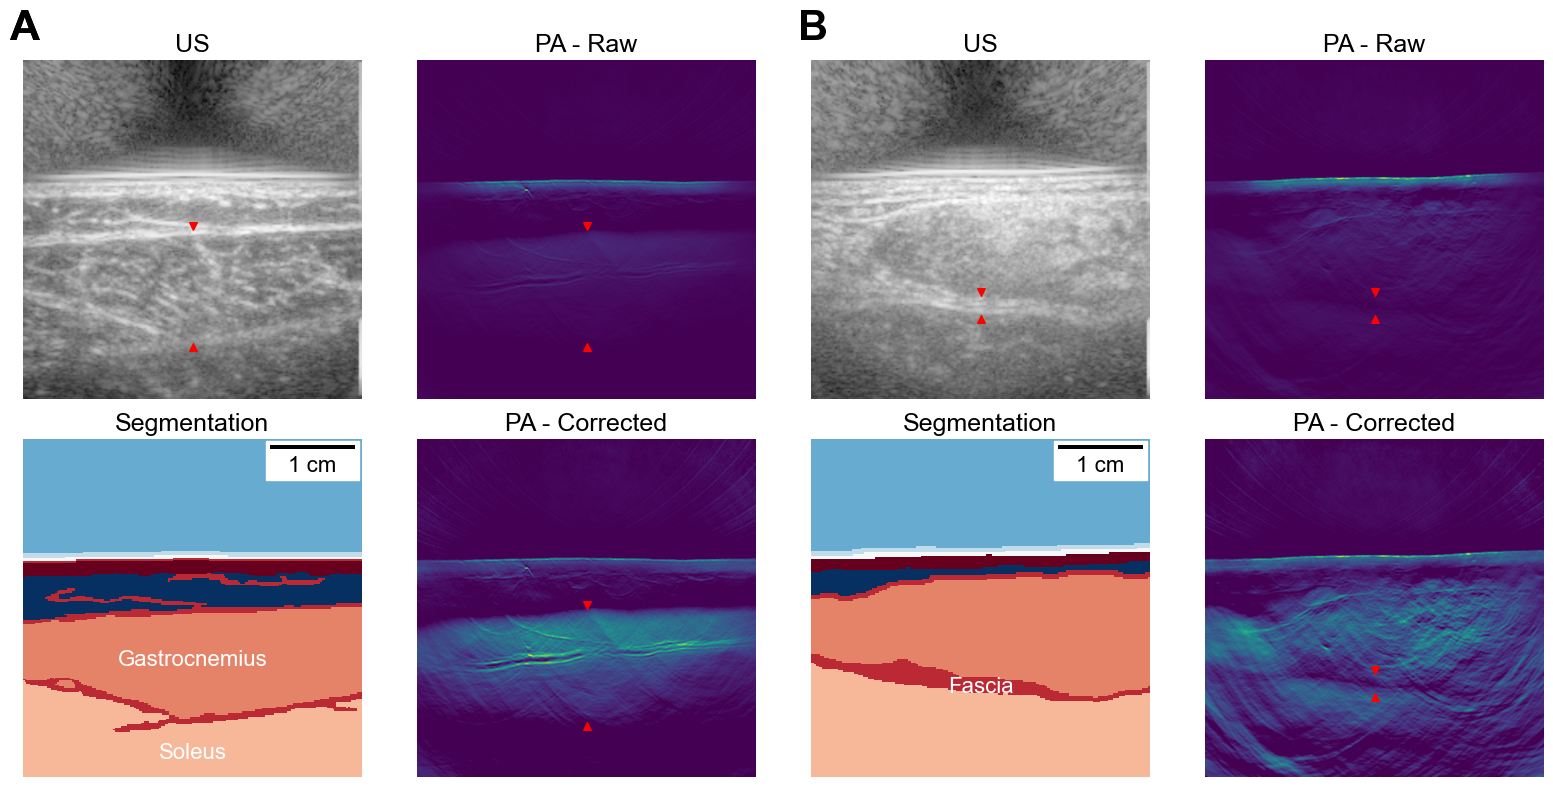

In [ ]:
plt.rcParams.update({
    "font.family": "arial",
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

marker_kw = dict(c='r', s=30)

def add_markers(ax, top, bot):
    ax.scatter(200, top - 10, marker="v", **marker_kw)
    ax.scatter(200, bot + 10, marker="^", **marker_kw)

# --- Panel A: sample 25_9 ---
top_25, bot_25 = 206, 329

axes[0, 0].imshow(us_img_25, cmap='gray')
axes[0, 1].imshow(oa_raw_25, cmap='viridis')
axes[1, 1].imshow(oa_correct_25, cmap='viridis')
axes[1, 0].imshow(seg_mask_25, cmap=cmap, norm=norm, interpolation='nearest')
axes[1, 0].text(200, 260, 'Gastrocnemius', color='white', ha='center', va='center')
axes[1, 0].text(200, 370, 'Soleus',        color='white', ha='center', va='center')
for ax in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    add_markers(ax, top_25, bot_25)

# --- Panel B: sample 90_9 ---
top_90, bot_90 = 283, 295 

axes[0, 2].imshow(us_img_90, cmap='gray')
axes[0, 3].imshow(oa_raw_90, cmap='viridis')
axes[1, 3].imshow(oa_correct_90, cmap='viridis')
axes[1, 2].imshow(seg_mask_90, cmap=cmap, norm=norm, interpolation='nearest')
axes[1, 2].text(200, top_90 + 10, 'Fascia', color='white', ha='center', va='center')
for ax in [axes[0, 2], axes[0, 3], axes[1, 3]]:
    add_markers(ax, top_90, bot_90)

titles = ["US", "PA — Raw", "US", "PA — Raw",
          "Segmentation", "PA — Corrected", "Segmentation", "PA — Corrected"]
for ax, title in zip(axes.flat, titles):
    ax.set_title(title)
    ax.axis('off')

# Panel labels
axes[0, 0].text(0.05, 1.15, 'A', transform=axes[0, 0].transAxes, fontsize=30, fontweight='bold', va='top', ha='right')
axes[0, 2].text(0.05, 1.15, 'B', transform=axes[0, 2].transAxes, fontsize=30, fontweight='bold', va='top', ha='right')

# Scale bars
axes[1, 0].add_artist(ScaleBar(0.1, "mm", length_fraction=0.25))
axes[1, 2].add_artist(ScaleBar(0.1, "mm", length_fraction=0.25))

plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/pad_samples.pdf", bbox_inches='tight', dpi=300)
plt.show()

## SNR

In [ ]:

def compute_snr(image, background_mask):
    """
    Compute SNR for an image using a background mask
    """

    # Extract background values
    bg_values = image[background_mask]

    # Compute SNR
    snr = np.mean(image) / np.std(bg_values)

    return snr

background_mask = np.zeros_like(oa_raw_90, dtype=bool)
background_mask[0:100, 150:250] = True 

snr_value_90_raw = compute_snr(oa_raw_90, background_mask)
snr_value_90_raw_db = 20 * np.log10(snr_value_90_raw)
print(f"SNR 90 raw: {snr_value_90_raw:.2f} ({snr_value_90_raw_db:.2f} dB)")

snr_value_90_corrected = compute_snr(oa_correct_90, background_mask)
snr_value_90_corrected_db = 20 * np.log10(snr_value_90_corrected)
print(f"SNR 90 corrected: {snr_value_90_corrected:.2f} ({snr_value_90_corrected_db:.2f} dB)")

snr_value_25_raw = compute_snr(oa_raw_25, background_mask)
snr_value_25_raw_db = 20 * np.log10(snr_value_25_raw)
print(f"SNR 25 raw: {snr_value_25_raw:.2f} ({snr_value_25_raw_db:.2f} dB)")

snr_value_25_corrected = compute_snr(oa_correct_25, background_mask)
snr_value_25_corrected_db = 20 * np.log10(snr_value_25_corrected)
print(f"SNR 25 corrected: {snr_value_25_corrected:.2f} ({snr_value_25_corrected_db:.2f} dB)")


SNR 90 raw: 4.51 (13.09 dB)
SNR 90 corrected: 10.56 (20.47 dB)
SNR 25 raw: 5.93 (15.46 dB)
SNR 25 corrected: 10.92 (20.76 dB)
